In [ ]:
#!pip -q install transformers datasets scikit-learn matplotlib
# %pip install -U ipywidgets

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          BertConfig, get_linear_schedule_with_warmup)
from IPython.display import display

DATA_PATH = "/content/IMDB Dataset.csv" # cột: review, sentiment
DOMAIN_B_PATH = "/content/domain_b.csv" # (tuỳ chọn) cột: text, label (1=positive, 0=negative)
RESULTS_PATH = "/content/results.csv"
OUT_DIR = "/content"

# DATA_PATH = "../data/IMDB Dataset.csv"
# DOMAIN_B_PATH = "../data/domain_b.csv"
# RESULTS_PATH = "results.csv"
# OUT_DIR = "."

RESET = True
IMG_FILES = ["data_efficiency.png", "confusion_matrix.png", "confidence_analysis.png"]
if RESET:
    for f in [RESULTS_PATH] + [os.path.join(OUT_DIR, x) for x in IMG_FILES]:
        if os.path.exists(f):
            os.remove(f)

MODEL_NAME = "bert-base-uncased"
SEED = 42
N_TRAIN, N_VAL, N_TEST = 10000, 1000, 2000
N_TEST_B = 2000 # số mẫu test của domain B
EPOCHS = 2
BATCH_SIZE = 32
MAX_LEN = 128 # max length mặc định
LR = {"finetune": 2e-5, "frozen": 1e-3, "scratch": 5e-4}
FRACS = [0.10, 0.25, 0.50, 1.00] # Exp 3
LENS = [64, 128, 256] # Exp 4
INCLUDE_SCRATCH_CURVE = True # Exp 3: vẽ thêm đường from-scratch để so sánh
HIGH_T, MED_T = 0.90, 0.70 # ngưỡng confidence

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("Device:", device, "|", HARDWARE)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

Device: cuda | Tesla T4


In [2]:
df = pd.read_csv(DATA_PATH)
df["text"] = df["review"].str.replace("<br />", " ", regex=False)
df["label"] = (df["sentiment"] == "positive").astype(int)
df = df.sample(N_TRAIN + N_VAL + N_TEST, random_state=SEED)

train_df, rest = train_test_split(df, train_size=N_TRAIN, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(rest, train_size=N_VAL, stratify=rest["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
print(len(train_df), len(val_df), len(test_df))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

10000 1000 2000


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [3]:
# tokenize (tên split, max_len)
_enc_cache = {}
def tokenize(texts, max_len):
    enc = tokenizer(list(texts), padding="max_length", truncation=True,
                    max_length=max_len, return_tensors="pt")
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]}

def get_enc(name, texts, max_len):
    key = (name, max_len)
    if key not in _enc_cache:
        _enc_cache[key] = tokenize(texts, max_len)
    return _enc_cache[key]

# model
def build_model(mode):
    if mode == "scratch": # Transformer nhỏ, khởi tạo ngẫu nhiên (cùng tokenizer)
        cfg = BertConfig(vocab_size=tokenizer.vocab_size, hidden_size=128, num_hidden_layers=2,
                         num_attention_heads=4, intermediate_size=256,
                         max_position_embeddings=512, num_labels=2)
        return AutoModelForSequenceClassification.from_config(cfg)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    if mode == "frozen": # đóng băng encoder, chỉ train classification head
        for p in model.base_model.parameters():
            p.requires_grad = False
    return model

# predict / metrics
use_amp = device.type == "cuda"

@torch.no_grad()
def predict(model, enc, bs=128):
    model.eval()
    out = []
    for i in range(0, len(enc["input_ids"]), bs):
        ids = enc["input_ids"][i:i+bs].to(device)
        mask = enc["attention_mask"][i:i+bs].to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=ids, attention_mask=mask).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu())
    return torch.cat(out).numpy()          # (N, 2) xác suất

def compute_metrics(y, probs):
    pred = probs.argmax(1)
    return {"accuracy": round(accuracy_score(y, pred), 4),
            "precision": round(precision_score(y, pred, zero_division=0), 4),
            "recall": round(recall_score(y, pred, zero_division=0), 4),
            "f1": round(f1_score(y, pred, zero_division=0), 4)}

# train
def train_model(model, enc, labels, lr, val_enc, val_labels):
    ds = TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(labels))
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    total = EPOCHS * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    for ep in range(EPOCHS):
        model.train()
        loss_sum = 0.0
        for ids, mask, y in loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = model(input_ids=ids, attention_mask=mask, labels=y).loss
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.item()
        val_acc = accuracy_score(val_labels, predict(model, val_enc).argmax(1))
        print(f"  epoch {ep+1}/{EPOCHS} | train loss {loss_sum/len(loader):.4f} | val acc {val_acc:.4f}")

def log_result(row):
    pd.DataFrame([row]).to_csv(RESULTS_PATH, mode="a", index=False,
                               header=not os.path.exists(RESULTS_PATH))

def run_experiment(experiment, run_name, mode, frac=1.0, max_len=MAX_LEN, keep_model=False):
    """Train 1 model, đánh giá trên test IMDb, ghi 1 dòng vào results.csv.
    Trả về (row, model hoặc None, test_probs)."""
    print(f"\n>>> {experiment} | {run_name} | mode={mode} | frac={frac} | max_len={max_len}")
    set_seed()
    n = int(len(train_df) * frac)
    enc_full = get_enc("train", train_df["text"], max_len)
    enc_tr = {k: v[:n] for k, v in enc_full.items()} # tập con lồng nhau (đã shuffle)
    enc_val = get_enc("val", val_df["text"], max_len)
    enc_te = get_enc("test", test_df["text"], max_len)

    model = build_model(mode).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    t0 = time.time()
    train_model(model, enc_tr, y_train[:n], LR[mode], enc_val, y_val)
    if device.type == "cuda":
        torch.cuda.synchronize()
    train_time = round(time.time() - t0, 1)
    peak_mem = round(torch.cuda.max_memory_allocated() / 2**20, 1) if device.type == "cuda" else np.nan

    probs = predict(model, enc_te)
    row = {"experiment": experiment, "run_name": run_name,
           "model": "bert-tiny-scratch" if mode == "scratch" else MODEL_NAME,
           "mode": mode, "train_frac": frac, "n_train": n, "max_len": max_len,
           "epochs": EPOCHS, "lr": LR[mode],
           "train_domain": "imdb", "test_domain": "imdb",
           **compute_metrics(y_test, probs),
           "train_time_s": train_time, "n_params": n_params, "n_trainable": n_trainable,
           "peak_mem_mb": peak_mem, "seed": SEED, "hardware": HARDWARE,
           "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")}
    log_result(row)
    print(f"  TEST acc={row['accuracy']} f1={row['f1']} | time={train_time}s")

    if not keep_model:
        del model
        model = None
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return row, model, probs

def reuse(row, experiment, run_name=None):
    """Dùng lại kết quả của 1 run đã có cho experiment khác (ghi thêm 1 dòng với nhãn mới)."""
    new = {**row, "experiment": experiment, "run_name": run_name or row["run_name"]}
    log_result(new)
    return new

SHOW_COLS = ["run_name", "mode", "train_frac", "n_train", "max_len", "train_domain", "test_domain",
             "accuracy", "precision", "recall", "f1", "train_time_s", "n_params", "n_trainable", "peak_mem_mb"]
def show(experiment):
    d = pd.read_csv(RESULTS_PATH)
    display(d[d["experiment"] == experiment][SHOW_COLS].reset_index(drop=True))

### 14. Experiment 1: Pretrained vs From Scratch
Cùng dataset, split, max length, số epoch. Model A: Transformer nhỏ khởi tạo ngẫu nhiên. Model B: pretrained + fine-tuning toàn bộ.

In [4]:
res_scratch, _, _ = run_experiment("exp1", "scratch", "scratch")
res_ft, main_model, main_probs = run_experiment("exp1", "pretrained_finetune", "finetune", keep_model=True)
show("exp1")


>>> exp1 | scratch | mode=scratch | frac=1.0 | max_len=128
  epoch 1/2 | train loss 0.5409 | val acc 0.8250
  epoch 2/2 | train loss 0.2484 | val acc 0.8280
  TEST acc=0.819 f1=0.8217 | time=18.5s

>>> exp1 | pretrained_finetune | mode=finetune | frac=1.0 | max_len=128


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.3952 | val acc 0.8530
  epoch 2/2 | train loss 0.2256 | val acc 0.8580
  TEST acc=0.8705 f1=0.8773 | time=130.5s


,run_name,mode,train_frac,n_train,max_len,train_domain,test_domain,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,peak_mem_mb
0,scratch,scratch,1.0,10000,128,imdb,imdb,0.8190,0.8201,0.8233,0.8217,18.5,4254594,4254594,136.1
1,pretrained_finetune,finetune,1.0,10000,128,imdb,imdb,0.8705,0.8434,0.9141,0.8773,130.5,109483778,109483778,3084.9


### 15. Experiment 2: Feature Extraction (Frozen) vs Fine-Tuning
Frozen: chỉ train classification head. Fine-tuning dùng lại kết quả từ Exp 1.

In [5]:
run_experiment("exp2", "frozen", "frozen")
reuse(res_ft, "exp2", "finetune")
show("exp2")


>>> exp2 | frozen | mode=frozen | frac=1.0 | max_len=128


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.6421 | val acc 0.6610
  epoch 2/2 | train loss 0.5924 | val acc 0.6950
  TEST acc=0.697 f1=0.734 | time=39.6s


,run_name,mode,train_frac,n_train,max_len,train_domain,test_domain,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,peak_mem_mb
0,frozen,frozen,1.0,10000,128,imdb,imdb,0.6970,0.6609,0.8253,0.7340,39.6,109483778,1538,1667.3
1,finetune,finetune,1.0,10000,128,imdb,imdb,0.8705,0.8434,0.9141,0.8773,130.5,109483778,109483778,3084.9


### 16. Experiment 3: Lượng dữ liệu train (10 / 25 / 50 / 100%)
Validation/test giữ cố định. 100% dùng lại từ Exp 1.

In [6]:
for frac in FRACS:
    if frac == 1.0:
        reuse(res_ft, "exp3", "finetune_100")
        if INCLUDE_SCRATCH_CURVE:
            reuse(res_scratch, "exp3", "scratch_100")
        continue
    run_experiment("exp3", f"finetune_{int(frac*100)}", "finetune", frac=frac)
    if INCLUDE_SCRATCH_CURVE:
        run_experiment("exp3", f"scratch_{int(frac*100)}", "scratch", frac=frac)
show("exp3")


>>> exp3 | finetune_10 | mode=finetune | frac=0.1 | max_len=128


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.6619 | val acc 0.7670
  epoch 2/2 | train loss 0.4964 | val acc 0.8000
  TEST acc=0.7875 f1=0.7992 | time=15.4s

>>> exp3 | scratch_10 | mode=scratch | frac=0.1 | max_len=128
  epoch 1/2 | train loss 0.6962 | val acc 0.5060
  epoch 2/2 | train loss 0.6957 | val acc 0.5100
  TEST acc=0.5095 f1=0.6738 | time=0.8s

>>> exp3 | finetune_25 | mode=finetune | frac=0.25 | max_len=128


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.5456 | val acc 0.8460
  epoch 2/2 | train loss 0.3119 | val acc 0.8500
  TEST acc=0.843 f1=0.8486 | time=35.2s

>>> exp3 | scratch_25 | mode=scratch | frac=0.25 | max_len=128
  epoch 1/2 | train loss 0.6950 | val acc 0.4940
  epoch 2/2 | train loss 0.6255 | val acc 0.7530
  TEST acc=0.726 f1=0.7373 | time=2.4s

>>> exp3 | finetune_50 | mode=finetune | frac=0.5 | max_len=128


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.4618 | val acc 0.8590
  epoch 2/2 | train loss 0.2604 | val acc 0.8590
  TEST acc=0.86 f1=0.8655 | time=72.6s

>>> exp3 | scratch_50 | mode=scratch | frac=0.5 | max_len=128
  epoch 1/2 | train loss 0.6714 | val acc 0.6980
  epoch 2/2 | train loss 0.3505 | val acc 0.7980
  TEST acc=0.795 f1=0.8095 | time=8.0s


,run_name,mode,train_frac,n_train,max_len,train_domain,test_domain,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,peak_mem_mb
0,finetune_10,finetune,0.10,1000,128,imdb,imdb,0.7875,0.7663,0.8351,0.7992,15.4,109483778,109483778,3944.9
1,scratch_10,scratch,0.10,1000,128,imdb,imdb,0.5095,0.5080,1.0000,0.6738,0.8,4254594,4254594,1004.8
2,finetune_25,finetune,0.25,2500,128,imdb,imdb,0.8430,0.8294,0.8687,0.8486,35.2,109483778,109483778,3944.9
3,scratch_25,scratch,0.25,2500,128,imdb,imdb,0.7260,0.7167,0.7591,0.7373,2.4,4254594,4254594,1004.8
4,finetune_50,finetune,0.50,5000,128,imdb,imdb,0.8600,0.8428,0.8894,0.8655,72.6,109483778,109483778,3944.9
5,scratch_50,scratch,0.50,5000,128,imdb,imdb,0.7950,0.7647,0.8598,0.8095,8.0,4254594,4254594,1004.8
6,finetune_100,finetune,1.00,10000,128,imdb,imdb,0.8705,0.8434,0.9141,0.8773,130.5,109483778,109483778,3084.9
7,scratch_100,scratch,1.00,10000,128,imdb,imdb,0.8190,0.8201,0.8233,0.8217,18.5,4254594,4254594,136.1


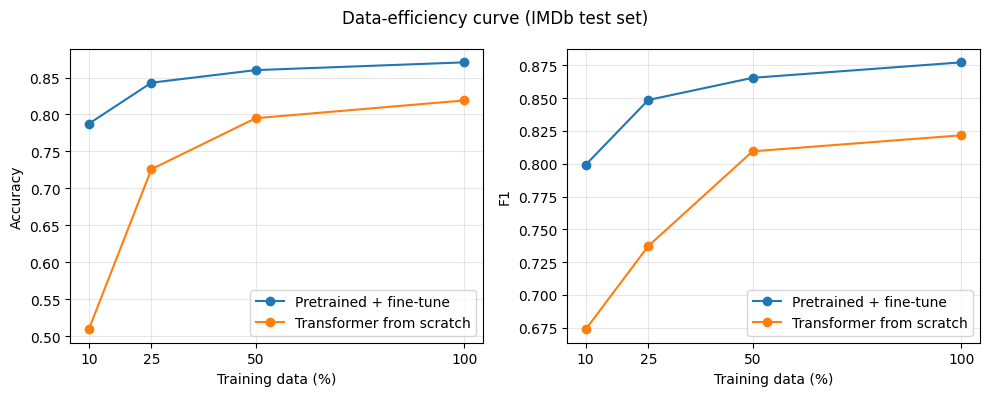

In [7]:
# data_efficiency.png
d3 = pd.read_csv(RESULTS_PATH)
d3 = d3[d3["experiment"] == "exp3"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["accuracy", "f1"]):
    for mode, label in [("finetune", "Pretrained + fine-tune"), ("scratch", "Transformer from scratch")]:
        s = d3[d3["mode"] == mode].sort_values("train_frac")
        if len(s):
            ax.plot(s["train_frac"] * 100, s[metric], marker="o", label=label)
    ax.set_xlabel("Training data (%)"); ax.set_ylabel(metric.upper() if metric == "f1" else "Accuracy")
    ax.set_xticks([10, 25, 50, 100]); ax.grid(alpha=0.3); ax.legend()
fig.suptitle("Data-efficiency curve (IMDb test set)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "data_efficiency.png"), dpi=150)
plt.show()

### 17. Experiment 4: Maximum Sequence Length (64 / 128 / 256)


In [8]:
for L in LENS:
    if L == MAX_LEN:
        reuse(res_ft, "exp4", f"finetune_len{L}")
        continue
    run_experiment("exp4", f"finetune_len{L}", "finetune", max_len=L)
show("exp4")


>>> exp4 | finetune_len64 | mode=finetune | frac=1.0 | max_len=64


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.4812 | val acc 0.8190
  epoch 2/2 | train loss 0.3046 | val acc 0.8290
  TEST acc=0.819 f1=0.8275 | time=99.1s

>>> exp4 | finetune_len256 | mode=finetune | frac=1.0 | max_len=256


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1/2 | train loss 0.3466 | val acc 0.8730
  epoch 2/2 | train loss 0.1770 | val acc 0.8930
  TEST acc=0.899 f1=0.9037 | time=236.1s


,run_name,mode,train_frac,n_train,max_len,train_domain,test_domain,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,peak_mem_mb
0,finetune_len64,finetune,1.0,10000,64,imdb,imdb,0.8190,0.8000,0.8569,0.8275,99.1,109483778,109483778,3159.0
1,finetune_len128,finetune,1.0,10000,128,imdb,imdb,0.8705,0.8434,0.9141,0.8773,130.5,109483778,109483778,3084.9
2,finetune_len256,finetune,1.0,10000,256,imdb,imdb,0.8990,0.8737,0.9358,0.9037,236.1,109483778,109483778,5557.5


### 18. Experiment 5: Domain Shift

In [9]:
if os.path.exists(DOMAIN_B_PATH):
    df_b = pd.read_csv(DOMAIN_B_PATH) # cột: text, label
else:
    from datasets import load_dataset
    for name in ["fancyzhx/yelp_polarity", "yelp_polarity"]:
        try:
            ds = load_dataset(name, split="test")
            break
        except Exception as e:
            print("Không tải được", name, "->", type(e).__name__)
    df_b = pd.DataFrame({"text": ds["text"], "label": ds["label"]})
df_b["text"] = df_b["text"].astype(str).str.replace("\\n", " ", regex=False)
df_b = df_b.sample(min(N_TEST_B, len(df_b)), random_state=SEED).reset_index(drop=True)
y_b = df_b["label"].values
print("Domain B:", len(df_b), "mẫu | tỉ lệ positive:", y_b.mean().round(3))

enc_b = tokenize(df_b["text"], MAX_LEN)
probs_b = predict(main_model, enc_b)
row_b = {**res_ft, "experiment": "exp5", "run_name": "imdb_to_yelp",
         "test_domain": "yelp", **compute_metrics(y_b, probs_b),
         "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")}
log_result(row_b)
reuse(res_ft, "exp5", "imdb_to_imdb")
show("exp5")

del main_model # giải phóng bộ nhớ; còn lại main_probs để vẽ ảnh
if device.type == "cuda":
    torch.cuda.empty_cache()

README.md:   0%|          | 0.00/8.93k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  256MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/560000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/38000 [00:00<?, ? examples/s]

Domain B: 2000 mẫu | tỉ lệ positive: 0.489


,run_name,mode,train_frac,n_train,max_len,train_domain,test_domain,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,peak_mem_mb
0,imdb_to_yelp,finetune,1.0,10000,128,imdb,yelp,0.8905,0.8563,0.9325,0.8928,130.5,109483778,109483778,3084.9
1,imdb_to_imdb,finetune,1.0,10000,128,imdb,imdb,0.8705,0.8434,0.9141,0.8773,130.5,109483778,109483778,3084.9


### 19. Application: Sentiment Classification (IMDb)
Model: pretrained Transformer fine-tune đầy đủ (Exp 1), đánh giá trên test IMDb. Metrics: Accuracy, Precision, Recall, F1 + confusion matrix.

,run_name,mode,train_frac,n_train,max_len,train_domain,test_domain,accuracy,precision,recall,f1,train_time_s,n_params,n_trainable,peak_mem_mb
0,imdb_sentiment,finetune,1.0,10000,128,imdb,imdb,0.8705,0.8434,0.9141,0.8773,130.5,109483778,109483778,3084.9


              precision    recall  f1-score   support

    negative     0.9035    0.8257    0.8629       987
    positive     0.8434    0.9141    0.8773      1013

    accuracy                         0.8705      2000
   macro avg     0.8734    0.8699    0.8701      2000
weighted avg     0.8731    0.8705    0.8702      2000



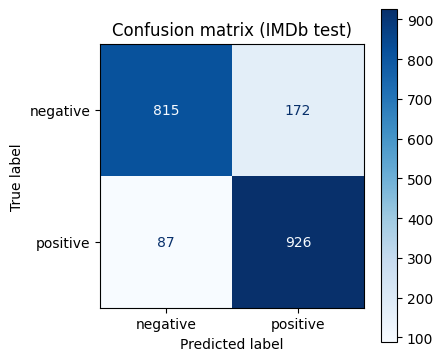

In [10]:
from sklearn.metrics import classification_report

pred_test = main_probs.argmax(1) # nhãn dự đoán
conf = main_probs.max(1) # confidence = xác suất lớn nhất
correct = pred_test == y_test

# ghi 1 dòng "app" vào results.csv
reuse(res_ft, "app", "imdb_sentiment")
show("app")

print(classification_report(y_test, pred_test, target_names=["negative", "positive"], digits=4))

# Confusion matrix
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["negative", "positive"],
                                        cmap="Blues", ax=ax)
ax.set_title("Confusion matrix (IMDb test)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

### 20. Error Analysis

In [11]:
res_df = test_df.copy()
res_df["pred"] = pred_test
res_df["confidence"] = conf.round(4)
res_df["correct"] = correct
wrong = res_df[~res_df["correct"]]

fp = wrong[(wrong["label"] == 0) & (wrong["pred"] == 1)]   # thật là negative, đoán positive
fn = wrong[(wrong["label"] == 1) & (wrong["pred"] == 0)]   # thật là positive, đoán negative
print(f"Tổng lỗi: {len(wrong)} | false positive: {len(fp)} | false negative: {len(fn)}")

fp_sel = fp.sample(min(3, len(fp)), random_state=SEED)
fn_sel = fn.sample(min(3, len(fn)), random_state=SEED)
# 2 mẫu sai có confidence cao nhất (không trùng với các mẫu đã chọn)
conf_sel = wrong.drop(fp_sel.index).drop(fn_sel.index).sort_values("confidence", ascending=False).head(2)

names = {0: "negative", 1: "positive"}
rows = []
for group, d in [("False positive", fp_sel), ("False negative", fn_sel), ("Confident wrong", conf_sel)]:
    for _, r in d.iterrows():
        rows.append({"Group": group, "Text": r["text"], "True": names[r["label"]],
                     "Pred": names[r["pred"]], "Confidence": r["confidence"],
                     "Error type": "", "Hypothesis": ""})
error_df = pd.DataFrame(rows) # error_df["Text"] chứa review đầy đủ

pd.set_option("display.max_colwidth", 400)
display(error_df.assign(Text=error_df["Text"].str[:400] + "..."))

Tổng lỗi: 259 | false positive: 172 | false negative: 87


,Group,Text,True,Pred,Confidence,Error type,Hypothesis
0,False positive,"With the plethora of repetitive and derivative sitcoms jamming fall, summer, winter and spring line-ups, it's nice to see a show that sets itself from the lot in more than one area. 'Earl' takes an unusual approach. It's not about the ""daily musings of an eccentric family"" (zzzz..) nor about the other boring stuff you see everywhere in sitcoms. The show is about this small-time white trash t...",negative,positive,0.8773,,
1,False positive,"Based on the comments made so far, everyone seems to either hate this movie or love it. I think it would be fair to point out that although this is not a GREAT movie, it has its interesting moments. For one thing, it was filmed on location in Colorado (was it Breckinridge or Telluride? I can't remember, but it is in the credits). The location is absolutely stunning and spectacular. It's beauti...",negative,positive,0.9835,,
2,False positive,"Violence whether real or not always has an impact. In this film the violence is about as crass as you could ask for. In the Great Ecstacy the director has successfully demonstrated what extremes of violence people are capable of. But what was the point? The violence looks like a mix of Noë's 'Irreversible, and ' Kubrick's 'Clockwork Orange'...both of which are remarkable films. Don't get me wr...",negative,positive,0.9235,,
3,False negative,"David Beckham is a British soccer star and the husband of Victoria Beckham (""Posh Spice"" of the Spice Girls). His trademark is a goal shot that curves across the pitch and into the net. The soccer equivalent of an unhittable curve ball in baseball. ""Bend it like Beckham"" means making that type of spectacular shot. Apart from that, and a little shrine to him in the main character's bedroom and ...",positive,negative,0.7401,,
4,False negative,"I would like to submit the following goof. During the bridge scene, soldiers are seen wading out in the river, asking to be taken away and seeking to escape. Some of the soldiers approach Captain Willard's boat and attempt to board carrying with them suitcases. Soldiers are not issued nor do they ever carry suitcases into a combat zone. They have duffel bags, packs and footlockers but not sui...",positive,negative,0.9542,,
5,False negative,"When I first heard of this movie, I was mildly interested. The plot seemed like an opportunity for hilarity and Bam Margera as an actor and director seemed like something that might be good. When I found out the movie starred Ryan Dunn, I was even further interested (I was a fan of Homewrecker when it was on... Yeah, I'm that lame). However, I didn't have much faith in it being to good. When I...",positive,negative,0.9575,,
6,Confident wrong,This was stupid funny movie.. Cheech and Chong are the dopiest wasted guys ever... i rate this film a 7.. but if you like this one then go see Jay and Silentbob! There funnier and crazier. Now Cheech is a sellout working on kids movies..... wheres chong?...,positive,negative,0.9897,,
7,Confident wrong,"By mistake, I ordered a series from the BBC, their new version of Robin Hood. Very disappointing in comparison with RoS. Terrible costuming and backgrounds. While I enjoyed the Sheriff, who took cues from the Nick Grace character, the rest of the cast left much to be desired. As a ""for instance"", Marion's costuming looked suspiciously like it came from Walmart. And Sir Guy, well, he looked a b...",positive,negative,0.9891,,


In [13]:
for i, r in error_df.iterrows():
    print(f"[{i}] {r['Group']} | true={r['True']} | pred={r['Pred']} | conf={r['Confidence']}")
    print(r["Text"], "\n" + "-" * 80)

[0] False positive | true=negative | pred=positive | conf=0.8773000240325928
With the plethora of repetitive and derivative sitcoms jamming fall, summer, winter and spring line-ups, it's nice to see a show that sets itself from the lot in more than one area.   'Earl' takes an unusual approach. It's not about the "daily musings of an eccentric family" (zzzz..) nor about the other boring stuff you see everywhere in sitcoms. The show is about this small-time white trash thief (Earl) who scratches off a lottery card and scores big time. Right at that moment, 'Karma' took it away from him. Overtime, he learns that that unusual incident was probably because of all the bad things he's been doing, so he sets off on a mission to right every wrong he ever did and he's got all his deeds on a paper.  This is a brilliant premise for a sitcom. Thankfully, it landed in the right hands. The execution of the show produces extremely satisfactory results: you get an innovative comedy that is genuinely fu

### 21. Confidence Analysis

,n,n_correct,n_wrong,accuracy
level,,,,
Low,173,94,79,0.5434
Medium,296,204,92,0.6892
High,1531,1443,88,0.9425


Confidence trung bình - mẫu đúng: 0.9385 | mẫu sai: 0.7915
Số mẫu sai nhưng confidence >= 0.9: 88 / 259 mẫu sai


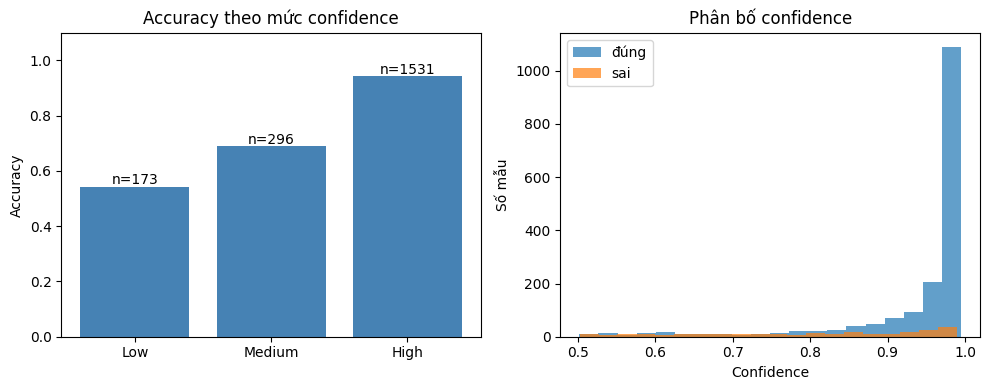

In [14]:
level = pd.cut(conf, [0, MED_T, HIGH_T, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)
tab = (pd.DataFrame({"level": level, "correct": correct})
         .groupby("level", observed=False)["correct"].agg(n="count", n_correct="sum"))
tab["n_wrong"] = tab["n"] - tab["n_correct"]
tab["accuracy"] = (tab["n_correct"] / tab["n"]).round(4)
display(tab)

print(f"Confidence trung bình - mẫu đúng: {conf[correct].mean():.4f} | mẫu sai: {conf[~correct].mean():.4f}")
print(f"Số mẫu sai nhưng confidence >= {HIGH_T}: {int(((~correct) & (conf >= HIGH_T)).sum())} / {int((~correct).sum())} mẫu sai")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(tab.index.astype(str), tab["accuracy"], color="steelblue")
for i, (n, a) in enumerate(zip(tab["n"], tab["accuracy"])):
    axes[0].text(i, a + 0.01, f"n={n}", ha="center")
axes[0].set_ylim(0, 1.1); axes[0].set_ylabel("Accuracy"); axes[0].set_title("Accuracy theo mức confidence")
axes[1].hist(conf[correct], bins=20, alpha=0.7, label="đúng")
axes[1].hist(conf[~correct], bins=20, alpha=0.7, label="sai")
axes[1].set_xlabel("Confidence"); axes[1].set_ylabel("Số mẫu"); axes[1].legend()
axes[1].set_title("Phân bố confidence")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confidence_analysis.png"), dpi=150)
plt.show()

### 22. Ablation / Analysis
A: Frozen vs Fine-tuned, B: 10% vs 100% data, C: sequence length, D: Pretrained vs From scratch

In [15]:
r = pd.read_csv(RESULTS_PATH)
def get(exp, name):
    return r[(r["experiment"] == exp) & (r["run_name"] == name)].iloc[0]

pairs = [("A. Frozen vs Fine-tuned", ("exp2", "frozen"), ("exp2", "finetune")),
         ("B. Pretrained: 10% vs 100% data", ("exp3", "finetune_10"), ("exp3", "finetune_100")),
         ("C. Seq length 64 vs 256", ("exp4", "finetune_len64"), ("exp4", "finetune_len256")),
         ("D. From scratch vs Pretrained", ("exp1", "scratch"), ("exp1", "pretrained_finetune"))]
if INCLUDE_SCRATCH_CURVE:
    pairs.append(("B'. Scratch: 10% vs 100% data", ("exp3", "scratch_10"), ("exp3", "scratch_100")))

table = []
for title, a, b in pairs:
    x, y = get(*a), get(*b)
    table.append({"Ablation": title, "Run 1": a[1], "Run 2": b[1],
                  "Acc 1": x["accuracy"], "Acc 2": y["accuracy"], "Δ Acc": round(y["accuracy"] - x["accuracy"], 4),
                  "F1 1": x["f1"], "F1 2": y["f1"], "Δ F1": round(y["f1"] - x["f1"], 4),
                  "Time 1 (s)": x["train_time_s"], "Time 2 (s)": y["train_time_s"]})
display(pd.DataFrame(table))

,Ablation,Run 1,Run 2,Acc 1,Acc 2,Δ Acc,F1 1,F1 2,Δ F1,Time 1 (s),Time 2 (s)
0,A. Frozen vs Fine-tuned,frozen,finetune,0.6970,0.8705,0.1735,0.7340,0.8773,0.1433,39.6,130.5
1,B. Pretrained: 10% vs 100% data,finetune_10,finetune_100,0.7875,0.8705,0.0830,0.7992,0.8773,0.0781,15.4,130.5
2,C. Seq length 64 vs 256,finetune_len64,finetune_len256,0.8190,0.8990,0.0800,0.8275,0.9037,0.0762,99.1,236.1
3,D. From scratch vs Pretrained,scratch,pretrained_finetune,0.8190,0.8705,0.0515,0.8217,0.8773,0.0556,18.5,130.5
4,B'. Scratch: 10% vs 100% data,scratch_10,scratch_100,0.5095,0.8190,0.3095,0.6738,0.8217,0.1479,0.8,18.5


### 23. Reproducibility

In [16]:
r = pd.read_csv(RESULTS_PATH)
times = r[r["experiment"] == "exp1"].set_index("run_name")["train_time_s"]

print("Model:", MODEL_NAME, "(from scratch: BertConfig, 2 layers, hidden 128, 4 heads)")
print("Tokenizer:", MODEL_NAME)
print("Dataset: IMDb (domain B cho Exp 5: Yelp polarity)")
print("Train split:", len(train_df))
print("Validation split:", len(val_df))
print("Test split:", len(test_df))
print("Max sequence length:", MAX_LEN, "(Exp 4:", LENS, ")")
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LR)
print("Epochs:", EPOCHS)
print("Optimizer: AdamW (weight_decay=0.01, linear schedule, warmup 6%)")
print("Random seed:", SEED)
print("Hardware:", HARDWARE)
print("Training time (Exp 1):", times.to_dict())
display(r.groupby("experiment").size().rename("số dòng trong results.csv"))

Model: bert-base-uncased (from scratch: BertConfig, 2 layers, hidden 128, 4 heads)
Tokenizer: bert-base-uncased
Dataset: IMDb (domain B cho Exp 5: Yelp polarity)
Train split: 10000
Validation split: 1000
Test split: 2000
Max sequence length: 128 (Exp 4: [64, 128, 256] )
Batch size: 32
Learning rate: {'finetune': 2e-05, 'frozen': 0.001, 'scratch': 0.0005}
Epochs: 2
Optimizer: AdamW (weight_decay=0.01, linear schedule, warmup 6%)
Random seed: 42
Hardware: Tesla T4
Training time (Exp 1): {'scratch': 18.5, 'pretrained_finetune': 130.5}


,số dòng trong results.csv
experiment,
app,1
exp1,2
exp2,2
exp3,8
exp4,3
exp5,2
